# Encoder: XLM-R base, head+tail
Fine-tuned on a fixed 40k stratified sample of the train fold, evaluated on the full val fold (same split as the baseline).

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)
from transformers.utils import logging as hf_logging

warnings.filterwarnings('ignore')
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

SEED = 42
MODEL = 'xlm-roberta-base'
TRAIN_N = 40_000
MAX_LEN = 512
HEAD = 128
LABELS = ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

set_seed(SEED)
INPUT = Path('/kaggle/input')
train = pd.read_parquet(next(INPUT.rglob('train_clean.parquet')))
test = pd.read_parquet(next(INPUT.rglob('test_clean.parquet')))
sample_sub = pd.read_csv(next(INPUT.rglob('sample_submission.csv')))

tr = train[train.fold == 'train']
tr = tr.groupby(['label', 'lang', 'domain'], group_keys=False).sample(frac=TRAIN_N / len(tr), random_state=SEED)
va = train[train.fold == 'val']
len(tr), len(va), len(test), torch.cuda.device_count()

(40001, 54537, 25000, 2)

## Head+tail tokenization
Texts longer than 510 tokens keep the first 128 and the last 382: fusion rewrites are mostly after the beginning.

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL)
tok.model_max_length = 10**6

def encode(texts):
    body = MAX_LEN - 2
    out = []
    for x in tok(list(texts), add_special_tokens=False)['input_ids']:
        if len(x) > body:
            x = x[:HEAD] + x[len(x) - (body - HEAD):]
        out.append([tok.cls_token_id] + x + [tok.sep_token_id])
    return out

class TextDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.ids = encode(df.text)
        self.labels = df.label.map(L2I).tolist() if 'label' in df else None

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        item = {'input_ids': self.ids[i]}
        if self.labels is not None:
            item['labels'] = self.labels[i]
        return item

ds_tr, ds_va, ds_te = TextDataset(tr), TextDataset(va), TextDataset(test)
ds_mon = torch.utils.data.Subset(ds_va, np.random.RandomState(SEED).choice(len(ds_va), min(5000, len(ds_va)), replace=False))
pd.Series([len(x) for x in ds_tr.ids]).describe().round(0)

count    40001.0
mean       429.0
std        138.0
min         24.0
25%        377.0
50%        512.0
75%        512.0
max        512.0
dtype: float64

## Training

In [3]:
def macro_f1(p):
    return {'macro_f1': f1_score(p.label_ids, p.predictions.argmax(-1), average='macro')}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I)

BATCH, ACCUM, EPOCHS = 8, 2, 2
steps = int(np.ceil(len(ds_tr) / (BATCH * ACCUM * max(torch.cuda.device_count(), 1)))) * EPOCHS

args = TrainingArguments(
    output_dir='out',
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=ACCUM,
    learning_rate=2e-5,
    num_train_epochs=EPOCHS,
    warmup_steps=int(.06 * steps),
    weight_decay=.01,
    lr_scheduler_type='linear',
    fp16=torch.cuda.is_available(),
    eval_strategy='steps',
    eval_steps=500,
    logging_steps=100,
    save_strategy='no',
    dataloader_num_workers=2,
    report_to='none',
    seed=SEED,
)
trainer = Trainer(model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_mon,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=macro_f1)
trainer.train()
trainer.save_model('xlmr_headtail')
tok.save_pretrained('xlmr_headtail')

Step,Training Loss,Validation Loss,Macro F1
500,1.417990,0.652249,0.836992
1000,1.032663,0.513064,0.878281
1500,0.745888,0.456257,0.899714
2000,0.652603,0.603981,0.869440
2500,0.571561,0.468260,0.903772
2502,0.571561,0.468230,0.903772


('xlmr_headtail/tokenizer_config.json', 'xlmr_headtail/tokenizer.json')

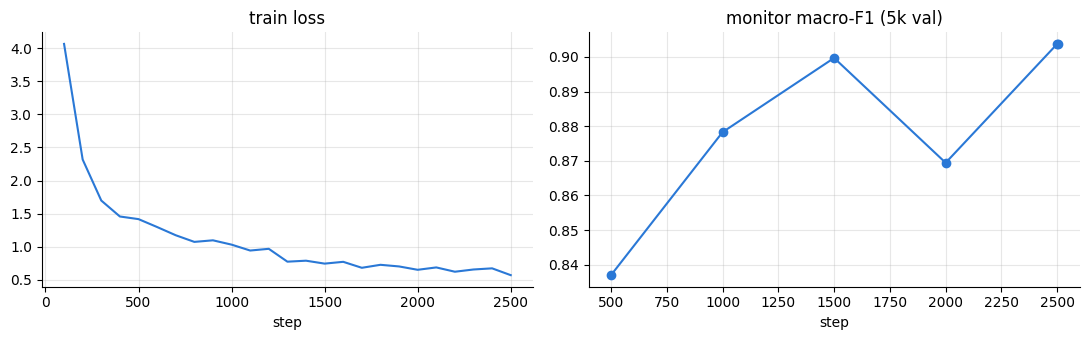

In [4]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
log.dropna(subset=['loss']).plot(x='step', y='loss', ax=ax[0], legend=False, title='train loss', color='#2a78d6')
log.dropna(subset=['eval_macro_f1']).plot(x='step', y='eval_macro_f1', ax=ax[1], legend=False, title='monitor macro-F1 (5k val)', marker='o', color='#2a78d6')
for a in ax:
    a.spines[['top', 'right']].set_visible(False)
    a.grid(alpha=.3)
plt.tight_layout()
plt.show()

## Validation (full val fold)

              precision    recall  f1-score   support

       human     0.8727    0.8153    0.8431     13408
          ai     0.9784    0.9967    0.9875     24375
      fusion     0.8632    0.8851    0.8740     16754

    accuracy                         0.9178     54537
   macro avg     0.9048    0.8991    0.9015     54537
weighted avg     0.9170    0.9178    0.9171     54537



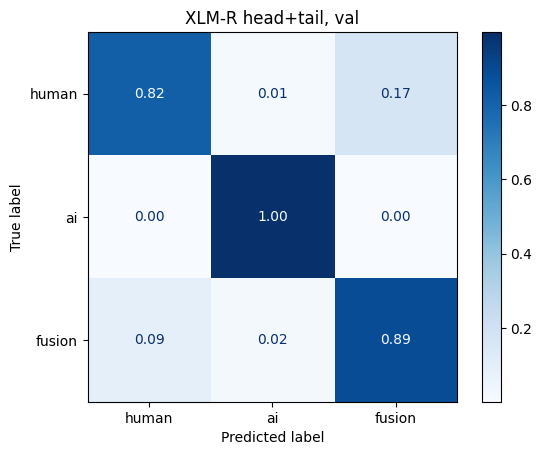

In [5]:
va_logits = trainer.predict(ds_va).predictions
va_pred = np.array(LABELS)[va_logits.argmax(-1)]
print(classification_report(va.label, va_pred, labels=LABELS, digits=4))
ConfusionMatrixDisplay.from_predictions(va.label, va_pred, labels=LABELS, normalize='true', cmap='Blues', values_format='.2f')
plt.title('XLM-R head+tail, val')
plt.show()

## Comparison with baseline
Same val ids. Needs `val_scores_baseline.csv` from the baseline notebook as input.

In [6]:
preds = {'xlmr_headtail': pd.Series(va_pred, index=va.id)}
base_path = next(INPUT.rglob('val_scores_baseline.csv'), None)
if base_path:
    preds['baseline'] = pd.read_csv(base_path, index_col='id').loc[va.id].idxmax(axis=1)

y = va.set_index('id').label
def scores(p):
    f = f1_score(y, p.loc[y.index], labels=LABELS, average=None)
    return {**dict(zip(LABELS, f)), 'macro': f.mean()}

pd.DataFrame({k: scores(p) for k, p in preds.items()}).T.round(4)

,human,ai,fusion,macro
xlmr_headtail,0.8431,0.9875,0.874,0.9015


In [7]:
v = va.set_index('id')
pd.DataFrame({
    k: pd.concat({by: v.assign(pred=p.loc[v.index]).groupby(by).apply(lambda d: f1_score(d.label, d.pred, average='macro'))
                  for by in ['lang', 'domain']})
    for k, p in preds.items()
}).round(4)

xlmr_headtail
lang   de-DE                          0.9024
       en-EN                          0.9013
domain arxiv_papers                   0.7684
       blog_authorship_corpus         0.8246
       bundestag                      0.9026
       cnn_news                       0.9526
       euro_court_cases               0.8331
       gutenberg                      0.6958
       house_of_commons               0.9379
       student_essays                 0.9322

## Save logits and submission

In [8]:
te_logits = trainer.predict(ds_te).predictions
pd.DataFrame(va_logits, columns=LABELS, index=va.id).to_csv('val_logits_xlmr_headtail.csv')
pd.DataFrame(te_logits, columns=LABELS, index=test.id).to_csv('test_logits_xlmr_headtail.csv')

pred = pd.Series(np.array(LABELS)[te_logits.argmax(-1)], index=test.id)
sample_sub.assign(label=pred.loc[sample_sub.id].values).to_csv('submission_xlmr_headtail.csv', index=False)
pd.read_csv('submission_xlmr_headtail.csv').label.value_counts(normalize=True).round(3)

label
ai        0.523
fusion    0.246
human     0.231
Name: proportion, dtype: float64